## Important libraries and load data


In [84]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv("example.csv")

### EXplore the dataset


In [85]:
print(df.head())
print(df.shape)
print(df.columns)
print(df.info())
print(df.describe())


   StudentID          Name  Age  Gender        Department  MathScore  \
0          1  Aarav Sharma   20    Male  Computer Science         88   
1          2  Ananya Patel   21  Female       Mathematics         95   
2          3   Rohan Verma   20    Male           Physics         44   
3          4    Priya Nair   22  Female           Biology         82   
4          5  Vikram Singh   21    Male  Computer Science         91   

   ScienceScore  EnglishScore   GPA  
0            92            85  3.75  
1            89            91  3.90  
2            80            78  3.10  
3            85            88  3.50  
4            94            84  3.82  
(100, 9)
Index(['StudentID', 'Name', 'Age', 'Gender', 'Department', 'MathScore',
       'ScienceScore', 'EnglishScore', 'GPA'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   StudentID

### check missing values

In [86]:
print(df.isnull().sum())
print(df.isnull().sum().sum())

StudentID       0
Name            0
Age             0
Gender          0
Department      0
MathScore       0
ScienceScore    0
EnglishScore    0
GPA             0
dtype: int64
0


### Remove missing rows

In [87]:
df.dropna(inplace=True)

### Fill missing values:

In [88]:
df["Age"] = df["Age"].fillna(df["Age"].median())

### Check and remove duplicate

In [89]:
print(df.duplicated().sum())

df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)

0


### Check data types

In [90]:
print(df.dtypes)

StudentID         int64
Name                str
Age               int64
Gender              str
Department          str
MathScore         int64
ScienceScore      int64
EnglishScore      int64
GPA             float64
dtype: object


### Step 6: Outlier Detection using IQR
IQR stands for Interquartile Range.

It measures the spread of the middle 50% of the data.

There are three important values:
- Q1: 25th percentile.
- Q2: 50th percentile (median).
- Q3: 75th percentile.
Formula:
\[
IQR = Q3-Q1
\]

Outlier boundaries:
\[
Lower=Q1-1.5\times IQR
\]

\[
Upper=Q3+1.5\times IQR
\]

Any value below the lower boundary or above the upper boundary is flagged as a potential outlier.

In [91]:
Q1 = df["MathScore"].quantile(0.25)
Q3 = df["MathScore"].quantile(0.75)

IQR = Q3 - Q1
print("IQR:", IQR)
print("Q1:", Q1)
print("Q3:", Q3)

IQR: 14.0
Q1: 76.0
Q3: 90.0


### Calculate the outlier boundaries

In [92]:
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Lower Boundary:", lower)
print("Upper Boundary:", upper)

Lower Boundary: 55.0
Upper Boundary: 111.0


### Identify outliers
Check outliers in all three subject columns

In [93]:
score_columns = ["MathScore", "ScienceScore", "EnglishScore"]

for col in score_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) |
        (df[col] > upper)
    ]

    print("\nOutliers in", col)
    print(outliers[["StudentID", "Name", col]])


Outliers in MathScore
    StudentID           Name  MathScore
2           3    Rohan Verma         44
16         17   Karthik Iyer         51
19         20     Kavya Nair        120
26         27  Pratik Gandhi        130
32         33   Mayank Dubey         46

Outliers in ScienceScore
    StudentID              Name  ScienceScore
28         29  Harshvardhan Rao            32

Outliers in EnglishScore
    StudentID              Name  EnglishScore
43         44  Pallavi Deshmukh            22


### PLOT for all subject outliers

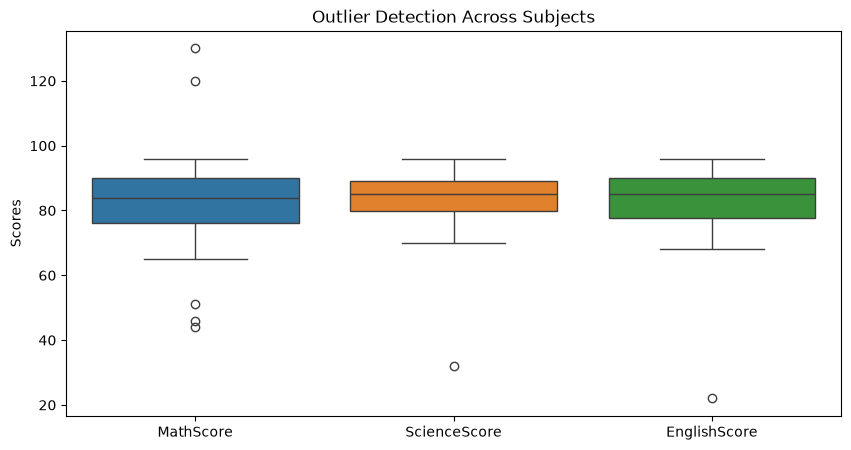

In [94]:
plt.figure(figsize=(10, 5))

sns.boxplot(data=df[
    ["MathScore", "ScienceScore", "EnglishScore"]
])

plt.title("Outlier Detection Across Subjects")
plt.ylabel("Scores")

plt.show()

In [95]:
score_columns = ["MathScore", "ScienceScore", "EnglishScore"]

for col in score_columns:
    invalid = df[(df[col] < 0) | (df[col] > 100)]

    print("\nInvalid values in", col)
    print(invalid[["StudentID", "Name", col]])


Invalid values in MathScore
    StudentID           Name  MathScore
19         20     Kavya Nair        120
26         27  Pratik Gandhi        130

Invalid values in ScienceScore
Empty DataFrame
Columns: [StudentID, Name, ScienceScore]
Index: []

Invalid values in EnglishScore
Empty DataFrame
Columns: [StudentID, Name, EnglishScore]
Index: []


### Impute missing values

In [96]:
df_clean = df.copy()
invalid = (
    (df_clean["MathScore"] < 0) |
    (df_clean["MathScore"] > 100)
)
print(df_clean[invalid])

df_clean.loc[invalid, "MathScore"] = np.nan

print(df_clean[df_clean["MathScore"].isnull()])

df_clean["MathScore"] = df_clean["MathScore"].fillna(df_clean["MathScore"].median())

    StudentID           Name  Age  Gender   Department  MathScore  \
19         20     Kavya Nair   20  Female      Biology        120   
26         27  Pratik Gandhi   22    Male  Mathematics        130   

    ScienceScore  EnglishScore   GPA  
19            89            91  3.85  
26            84            86  3.56  
    StudentID           Name  Age  Gender   Department  MathScore  \
19         20     Kavya Nair   20  Female      Biology        NaN   
26         27  Pratik Gandhi   22    Male  Mathematics        NaN   

    ScienceScore  EnglishScore   GPA  
19            89            91  3.85  
26            84            86  3.56  


### Phase 2
mean , median and mode

In [97]:
score_cols = [
    "MathScore",
    "ScienceScore",
    "EnglishScore",
    "GPA"
]

print(df[score_cols].mean())
print(df[score_cols].median())
print(df[score_cols].mode())

MathScore       82.7600
ScienceScore    83.7800
EnglishScore    83.2400
GPA              3.5791
dtype: float64
MathScore       84.00
ScienceScore    85.00
EnglishScore    85.00
GPA              3.53
dtype: float64
   MathScore  ScienceScore  EnglishScore   GPA
0       88.0          85.0            87  3.48
1        NaN           NaN            89   NaN


In [100]:

# range
score_range = df["MathScore"].max() - df["MathScore"].min()
print(score_range)

#variance
print(df["MathScore"].var())

#standard deviation
print(df["MathScore"].std())

#mad mean absolute deviation
mad = (df["MathScore"] - df["MathScore"].mean()).abs().mean()

print(mad)

86
139.2549494949495
11.800633436174072
8.519200000000001


### Histogram
Shows how numerical values are distributed.

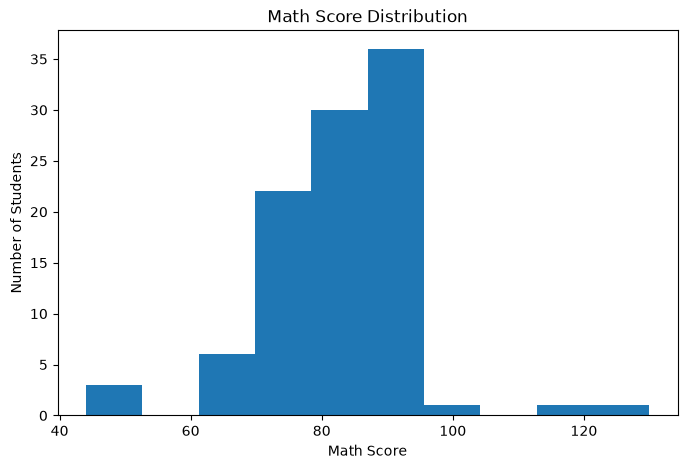

In [101]:
plt.figure(figsize=(8, 5))

plt.hist(df["MathScore"], bins=10)

plt.title("Math Score Distribution")
plt.xlabel("Math Score")
plt.ylabel("Number of Students")

plt.show()

### Boxplot
Helps identify outliers and understand the spread of data.

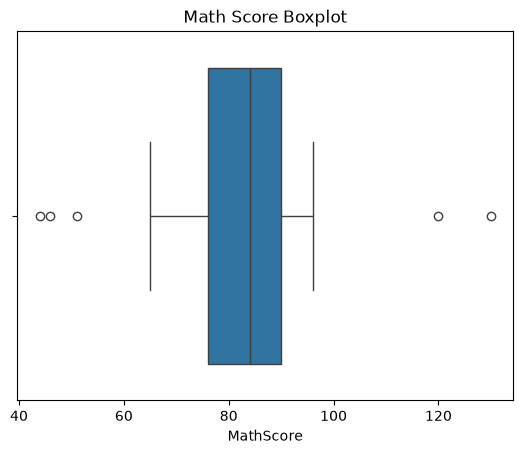

In [102]:
sns.boxplot(x=df["MathScore"])

plt.title("Math Score Boxplot")
plt.show()

### Scatter plot
Shows the relationship between two numerical variables.

For example, MathScore versus ScienceScore:

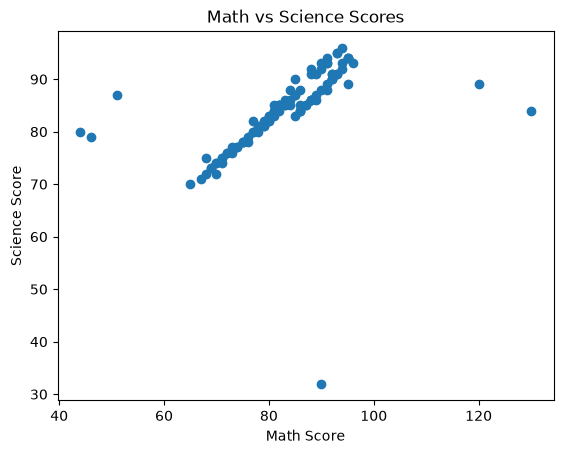

In [103]:
plt.scatter(df["MathScore"], df["ScienceScore"])

plt.title("Math vs Science Scores")
plt.xlabel("Math Score")
plt.ylabel("Science Score")

plt.show()


### Heatmap (correlation)
Shows correlations between numerical columns

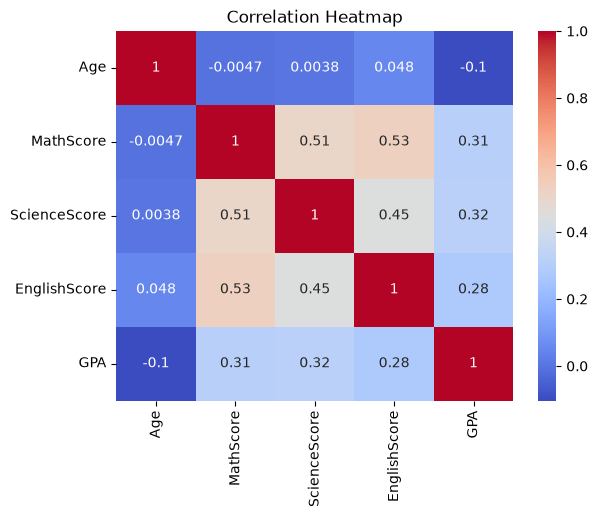

In [104]:
corr = df[["Age", "MathScore", "ScienceScore",
           "EnglishScore", "GPA"]].corr()

sns.heatmap(corr, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap")
plt.show()

In [105]:
score_cols = [
    "MathScore",
    "ScienceScore",
    "EnglishScore",
    "GPA"
]

print("DESCRIPTIVE STATISTICS")
print(df[score_cols].describe())

print("\nSKEWNESS")
print(df[score_cols].skew())

print("\nKURTOSIS")
print(df[score_cols].kurt())

print("\nDEPARTMENT FREQUENCY")
print(df["Department"].value_counts())

print("\nGENDER FREQUENCY")
print(df["Gender"].value_counts())

DESCRIPTIVE STATISTICS
        MathScore  ScienceScore  EnglishScore         GPA
count  100.000000    100.000000    100.000000  100.000000
mean    82.760000     83.780000     83.240000    3.579100
std     11.800633      8.296987      9.658952    0.861744
min     44.000000     32.000000     22.000000    2.650000
25%     76.000000     79.750000     77.750000    3.250000
50%     84.000000     85.000000     85.000000    3.530000
75%     90.000000     89.250000     90.000000    3.757500
max    130.000000     96.000000     96.000000    9.950000

SKEWNESS
MathScore       0.028360
ScienceScore   -2.510339
EnglishScore   -2.648386
GPA             5.667264
dtype: float64

KURTOSIS
MathScore        4.012356
ScienceScore    14.027740
EnglishScore    14.961104
GPA             37.922709
dtype: float64

DEPARTMENT FREQUENCY
Department
Computer Science    21
Mathematics         20
Physics             20
Biology             20
Chemistry           19
Name: count, dtype: int64

GENDER FREQUENCY
Gender
Ma

### We'll cover five important concepts:
1. Covariance
2. Correlation
3. Pearson correlation
4. Spearman correlation
5. Correlation heatmap and scatter plots

### 1. Covariance
Covariance tells us the direction in which two variables move together.

There are three possibilities:
Covariance	Meaning
Positive	Both variables tend to increase together
Negative	One increases while the other tends to decrease
Near zero	Little or no linear co-movement

In [106]:
covariance = df["MathScore"].cov(df["ScienceScore"])

print("Covariance:", covariance)

Covariance: 49.46181818181819


### To calculate covariance for all numerical columns:

In [107]:
numeric_df = df[
    ["Age", "MathScore", "ScienceScore", "EnglishScore", "GPA"]
]

print(numeric_df.cov())

                   Age   MathScore  ScienceScore  EnglishScore       GPA
Age           0.666263   -0.045253      0.025859      0.378586 -0.072745
MathScore    -0.045253  139.254949     49.461818     60.724848  3.125539
ScienceScore  0.025859   49.461818     68.840000     35.810909  2.280507
EnglishScore  0.378586   60.724848     35.810909     93.295354  2.303552
GPA          -0.072745    3.125539      2.280507      2.303552  0.742602


### Pearson correlation
Pearson correlation measures the strength and direction of a linear relationship between two numerical variables.

For example, MathScore and ScienceScore.

In [108]:
pearson_corr = df["MathScore"].corr(
    df["ScienceScore"],
    method="pearson"
)

print("Pearson Correlation:", pearson_corr)

Pearson Correlation: 0.5051778797165555


### 4. Spearman correlation
Spearman correlation measures the relationship between the ranks of two variables.

It is useful when:
- The relationship is monotonic but not necessarily linear.
- Data is ordinal or based on rankings.
- We want a rank-based measure that is less sensitive to extreme numerical values than Pearson.

In [109]:
spearman_corr = df["MathScore"].corr(
    df["ScienceScore"],
    method="spearman"
)

print("Spearman Correlation:", spearman_corr)

Spearman Correlation: 0.873713193041139


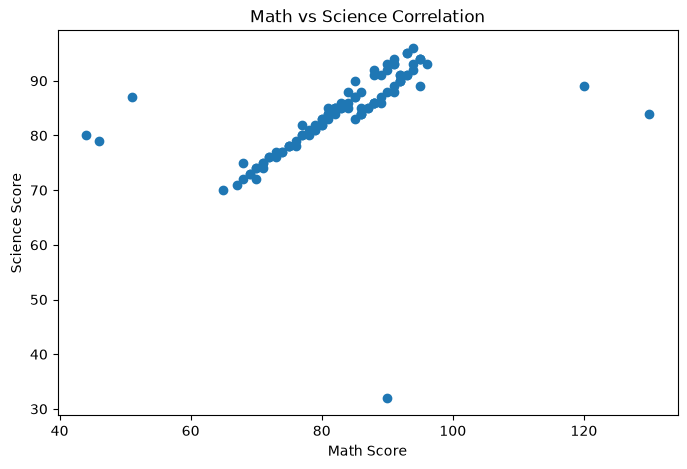

In [110]:
plt.figure(figsize=(8, 5))

plt.scatter(df["MathScore"], df["ScienceScore"])

plt.title("Math vs Science Correlation")
plt.xlabel("Math Score")
plt.ylabel("Science Score")

plt.show()

### Complete phase 4 together


In [111]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Load dataset
df = pd.read_csv("example.csv")

# Select features and target
X = df[
    ["MathScore", "ScienceScore", "EnglishScore"]
]

y = df["GPA"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create model
model = LinearRegression()

# Train model
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Evaluate
print("MAE:", mean_absolute_error(y_test, y_pred))

mse = mean_squared_error(y_test, y_pred)
print("MSE:", mse)

print("RMSE:", np.sqrt(mse))

print("R2 Score:", r2_score(y_test, y_pred))

MAE: 0.16635156602364906
MSE: 0.030690535311544715
RMSE: 0.1751871436822483
R2 Score: 0.7632286796773307
